# Code Execution with Energy Profiling

In [1]:
# Import modules
import lassi.code_manager
from lassi.get_power import report_gpu_memory
from lassi.format_colors import color

In [2]:
# Code to test and input parameters
folder = "test_codes/all-pairs-distance/"
code_filename = "all-pairs-distance-cuda_main.cu"
exe_input_parameters = ["10000"]

# Parameters
power_measure = True
source_language = "CUDA"
target_language = "CUDA"
build_script = False
code_compiler = "nvcc"
code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
# -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s  # -arch=sm_60 for P100

In [3]:
# Compile code
compile_result, execute_file = lassi.code_manager.compile_code(
    folder + '/' + code_filename,
    source_language,
    code_compiler,
    code_compiler_kwds
)

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main.cu', '-o', 'test_codes/all-pairs-distance//all-pairs-distance-cuda_main']

Compilation of code successful!




----- >>> System check BEFORE exe code...

----- GPU Memory Status:
 GPU 0: 637 MiB used, 40322 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 36.97 W, P0
210 MHz, 210 MHz, 31.27 W, P0



Waiting for the system to settle down for 5 seconds...: 100%|█████████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Working directory: test_codes/all-pairs-distance
Execute command: ['./all-pairs-distance-cuda_main', '10000']


----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

CPU time: 171054.000000 (us)
Average kernel execution time: 136.323502 (us)
PASS
Average kernel execution time: 140.714798 (us)
PASS
Average kernel execution time: 134.731506 (us)
PASS

----- < END: Standard Output > -----

GPU power data has been written to CUDA_CUDA_gpu_net_power_results.csv


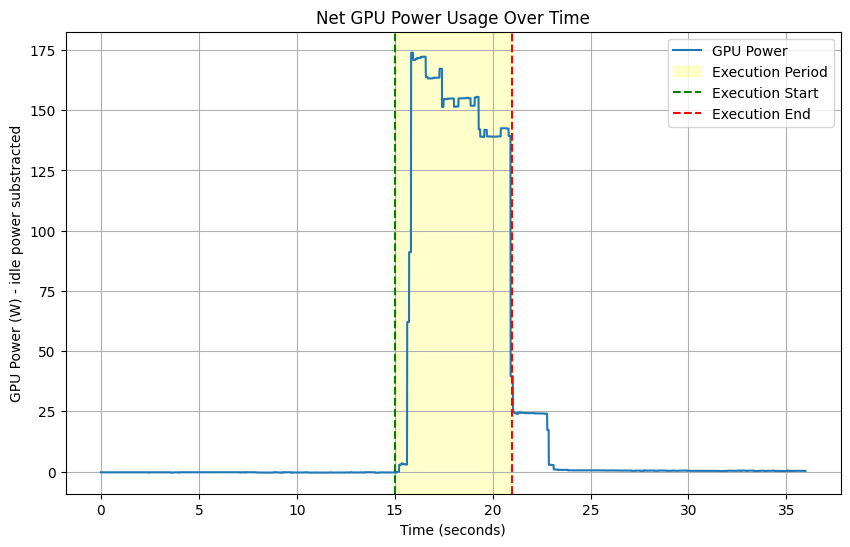

Start time: 15.016 -- End time: 20.964
Net (idle corrected) GPU energy consumption for CUDA_CUDA_gpu_net_power_results.csv:
  0.000222 kWh
  0.2224 Wh
  800.58 J
Average GPU power: 134.55 W +/- 49.47 
 with sample standard deviation.
Net Energy During Exe Runtime:   800.58 J
Code execution duration:  5.95 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 637 MiB used, 40322 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 37.56 W, P0
210 MHz, 210 MHz, 31.36 W, P0



In [4]:
# Execute code with Energy Profiling
execute_result, exe_output, total_energy_joules, ave_power, std_power, duration, metrics_results_string = lassi.code_manager.execute_code(
    execute_file,
    exe_input_parameters,
    power_measure,
    source_language,
    target_language,
    build_script,
    wait=5
)

## Optional - Measure system idle power
Using same runtime as code execution above.

Measure system idle power...
Duration for idle time measurement: 5.95
GPU power data has been written to idle__gpu_net_power_results.csv


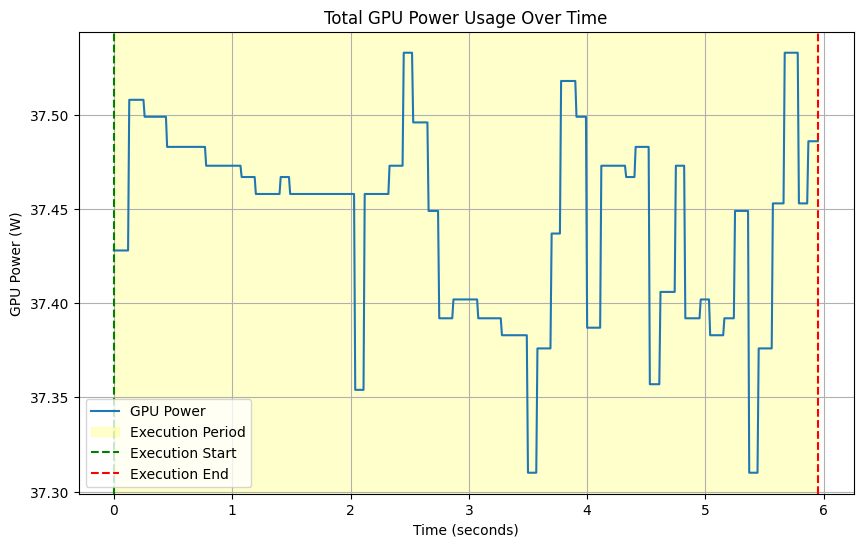

Start time: 0 -- End time: 5.955
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000062 kWh
  0.0620 Wh
  223.17 J
Average GPU power: 37.44 W +/- 0.05 
 with sample standard deviation.
Total Energy During Exe Runtime:   223.17 J
Code execution duration:  5.95 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Idle power measured values for same runtime as all-pairs-distance-cuda_main.cu
Average GPU power: 37.44 W +/- 0.05
Total Energy During Code Runtime: 223.17 J


In [5]:
# OPTIONAL
# Measure system idle power
print("Measure system idle power...")

idle_energy_joules, idle_ave_power, std_idle_ave_power = lassi.get_power.idlepower(duration)

print(color.BOLD + color.BLUE + "\nIdle power measured values for same runtime as " + color.END + str(code_filename))
print("Average GPU power: " + color.BOLD + f"{idle_ave_power:.2f} W +/- {std_idle_ave_power}" + color.END)
print("Total Energy During Code Runtime: " + color.BOLD + f"{idle_energy_joules:.2f} J" + color.END)